# 04 — Analysis and Scoring

**Objective:** Score all 30 vehicle-part combinations using a weighted priority formula, run a sensitivity analysis, and recommend the top 5 parts for import.

**Assignment requirements:**
- *"Create and justify your own scoring formula."*
- *"How each factor becomes a number"*
- *"Why each weight was chosen"*
- *"Whether changing the weights changes the ranking"*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned data
cleaned = pd.read_csv('../data/cleaned/cleaned_observations.csv')
print(f"Cleaned observations loaded: {len(cleaned)} rows")
cleaned.head()

Cleaned observations loaded: 59 rows


,observation_id,vehicle,model_year,part_category,part_description,oem_part_number,supplier,price,currency,availability,...,source_id,source_url,collection_date,evidence_type,notes,observation_type,price_usd,price_missing,is_cross_checked,compatibility_strength
0,OBS001,BYD Seagull,2023-2024,Bumper,Front Bumper,EQEA-2083111,Landin BYD Parts,198.0,RMB,listed_in_catalogue,...,S003,https://www.landinparts.com/p.html#/byd/byd002...,2026-11-18,supplier_catalogue,SKU: BYD0020040; Landin catalog extraction | O...,supplier_catalogue,27.72,False,False,catalogue_match
1,OBS002,BYD Seagull,2023-2024,Bumper,Front Bumper,EQEE-2803111,Landin BYD Parts,165.0,RMB,listed_in_catalogue,...,S003,https://www.landinparts.com/p.html#/byd/byd004...,2026-11-18,supplier_catalogue,SKU: BYD0040040U1; Landin catalog extraction,supplier_catalogue,23.10,False,False,catalogue_match
2,OBS003,BYD Seagull,2023-2024,Bumper,Front Bumper,EQEA-2803112,Landin BYD Parts,88.0,RMB,listed_in_catalogue,...,S003,https://www.landinparts.com/p.html#/byd/byd004...,2026-11-18,supplier_catalogue,SKU: BYD0040040L6; Landin catalog extraction,supplier_catalogue,12.32,False,False,catalogue_match
3,OBS004,BYD Seagull,2023-2024,Bumper,Rear Bumper,EQEA-2804110A/00,Landin BYD Parts,NaN,NaN,listed_in_catalogue,...,S003,https://www.landinparts.com/p.html#/byd/byd004...,2026-11-18,supplier_catalogue,SKU: BYD0040190; Landin catalog extraction,supplier_catalogue,NaN,True,False,catalogue_match
4,OBS005,BYD Seagull,2023-2024,Fender / body panel,Front Door Panel,EQEA-6101019/70,Landin BYD Parts,NaN,NaN,listed_in_catalogue,...,S003,https://www.landinparts.com/p.html#/byd/byd004...,2026-11-18,supplier_catalogue,SKU: BYD0040232; Landin catalog extraction,supplier_catalogue,NaN,True,False,catalogue_match


## 4.1 Scoring Model Design

### Five Scoring Factors

| Factor | Weight | What It Measures | Justification for Weight |
|--------|--------|------------------|-------------------------|
| **Demand evidence** | 30% | Evidence that the part may be needed in the target market | Highest weight because an importer's greatest risk is stocking parts nobody needs. NHTSA complaints, common wear patterns, and marketplace visibility all indicate potential demand. |
| **Market scarcity** | 25% | Evidence of a supply gap or limited local availability | Second-highest because if a part is already easily available locally, there is less business opportunity even if demand exists. |
| **Vehicle compatibility** | 20% | Strength of verified fitment evidence | Importing a wrong-fit part is costly (returns, customer trust). Verified OEM numbers reduce this risk. |
| **Sourcing practicality** | 15% | Ease of obtaining and importing the part | A part can have high demand but be impossible to source (no supplier, restricted, etc.). |
| **Evidence confidence** | 10% | Reliability and cross-checking of the evidence | Acts as a trust multiplier — it doesn't create opportunity, but validates other factors. Lowest weight because it measures our data quality, not market opportunity. |

**Weights total:** 30 + 25 + 20 + 15 + 10 = **100%**

### Rating Scale (1-5) for Each Factor

#### Demand Evidence (D)
| Score | Criteria |
|-------|----------|
| 5 | NHTSA complaints/recalls + marketplace evidence of replacement need |
| 4 | Multiple indicators: common wear item + vehicle has strong marketplace presence |
| 3 | Known wear item for this vehicle class (general automotive knowledge) |
| 2 | Vehicle is present in market but no specific part demand evidence |
| 1 | No evidence of demand found |

#### Market Scarcity (S)
| Score | Criteria |
|-------|----------|
| 5 | No local supplier found; not available through any Ethiopian distributor |
| 4 | Very limited availability (one source, long lead time) |
| 3 | Available internationally but unclear if imported to Ethiopia |
| 2 | Available through multiple international suppliers |
| 1 | Readily available locally or through established import channels |

#### Vehicle Compatibility (C)
| Score | Criteria |
|-------|----------|
| 5 | OEM part number confirmed by 2+ sources with exact vehicle fitment |
| 4 | OEM part number found in one catalogue with vehicle-specific listing |
| 3 | Part listed for the vehicle but no OEM number; supplier claims compatibility |
| 2 | Generic part listing — may fit but compatibility unverified |
| 1 | No compatibility evidence found |

#### Sourcing Practicality (P)
| Score | Criteria |
|-------|----------|
| 5 | Multiple international suppliers, clear pricing, in stock |
| 4 | At least one supplier with pricing; availability confirmed |
| 3 | Supplier found but price or availability unclear |
| 2 | Part exists in catalogues but no clear path to purchase |
| 1 | No supplier found |

#### Evidence Confidence (E)
| Score | Criteria |
|-------|----------|
| 5 | Cross-checked across 2+ independent sources; from identifiable manufacturer |
| 4 | One strong source (OEM catalogue or government database) |
| 3 | One reliable source (established parts supplier) |
| 2 | One source of uncertain reliability |
| 1 | No verifiable source; based on inference only |

In [2]:
# Define the scoring weights
WEIGHTS = {
    'demand_evidence': 0.30,
    'market_scarcity': 0.25,
    'vehicle_compatibility': 0.20,
    'sourcing_practicality': 0.15,
    'evidence_confidence': 0.10
}

print("Scoring weights:")
for factor, weight in WEIGHTS.items():
    print(f"  {factor}: {weight:.0%}")
print(f"  Total: {sum(WEIGHTS.values()):.0%}")

Scoring weights:
  demand_evidence: 30%
  market_scarcity: 25%
  vehicle_compatibility: 20%
  sourcing_practicality: 15%
  evidence_confidence: 10%
  Total: 100%


## 4.2 Assign Scores

Scores for all 30 vehicle-part combinations are **not** assigned inline in this notebook.
They are loaded from the authoritative scoring module `scrapper/generate_scores_defensible.py`
via its `get_scoring_data()` function, which holds the evidence-referenced factor scores and
per-combination justifications.

> **Relationship to the scoring module:** `scrapper/generate_scores_defensible.py` is the single
> source of truth for the factor scores and for the published `data/scoring_results.csv`. This
> notebook is a *consumer* of that module — it loads the scores, re-derives the weighted formula
> for transparency, runs the sensitivity analysis and renders the visuals. Because the scores live
> in the module, editing the raw dataset does not silently change them, and re-running this
> notebook cannot overwrite the published scoring table with placeholder values (see §4.6).

In [3]:
# Load the complete, evidence-justified scoring table for all 30 vehicle-part combinations
# from the authoritative scoring module. These are NOT placeholders: the factor scores and the
# per-combination justifications live in scrapper/generate_scores_defensible.py, so this notebook
# can never emit zero-filled or invented scores.
import sys
from pathlib import Path

# Make the repository root importable regardless of the kernel's working directory
_candidates = [Path.cwd(), *Path.cwd().parents]
_root = next(p for p in _candidates if (p / 'scrapper' / 'generate_scores_defensible.py').exists())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from scrapper.generate_scores_defensible import get_scoring_data

scores_data = get_scoring_data()
scores_df = pd.DataFrame(scores_data)

# Validate that the loaded table is complete and contains no placeholder values
_factor_cols = ['demand_evidence', 'market_scarcity', 'vehicle_compatibility',
                'sourcing_practicality', 'evidence_confidence']
assert len(scores_df) == 30, f"Expected 30 combinations, found {len(scores_df)}"
assert scores_df[_factor_cols].min().min() > 0, "Refusing to proceed: zero/placeholder score detected"

print(f"Scoring table loaded: {len(scores_df)} combinations across 3 vehicles and 10 categories.")
scores_df.head(10)

Scoring table loaded: 30 combinations across 3 vehicles and 10 categories.


,vehicle,part_category,demand_evidence,market_scarcity,vehicle_compatibility,sourcing_practicality,evidence_confidence,score_justification
0,BYD Seagull,Side mirror,5,4,5,4,5,D=5: High Adey Market presence (37 Seagull lis...
1,BYD Seagull,Brake pads,4,4,5,5,5,D=4: High Adey presence + routine friction wea...
2,BYD Seagull,Shock absorber,4,4,5,5,5,D=4: High Adey presence + suspension damping w...
3,BYD Seagull,Headlight assembly,4,4,5,4,5,D=4: High Adey presence + frontal collision da...
4,BYD Seagull,Bumper,4,4,5,5,5,D=4: High Adey presence + urban low-speed fron...
5,BYD Seagull,Brake discs,3,4,5,5,5,D=3: Slower wear cycle than pads due to EV reg...
6,BYD Seagull,Tail-light assembly,3,4,5,4,5,D=3: Rear impact replacement item; lower turno...
7,BYD Seagull,Fender / body panel,3,4,5,3,5,D=3: Collision-only sheet metal panels; slower...
8,BYD Seagull,Cabin-air filter,4,5,1,1,1,D=4: Routine air quality maintenance consumabl...
9,BYD Seagull,Wiper blades,4,3,1,1,1,D=4: Annual wear consumable (indicative demand...


## 4.3 Calculate Priority Scores

In [4]:
def calculate_priority_score(row, weights=WEIGHTS):
    """Calculate weighted priority score for a vehicle-part combination.
    
    Formula: Score = (w1 × D) + (w2 × S) + (w3 × C) + (w4 × P) + (w5 × E)
    Where each factor is rated 1-5 and weights sum to 1.0
    
    Returns a score between 1.0 (lowest priority) and 5.0 (highest priority).
    """
    score = (
        weights['demand_evidence'] * row['demand_evidence'] +
        weights['market_scarcity'] * row['market_scarcity'] +
        weights['vehicle_compatibility'] * row['vehicle_compatibility'] +
        weights['sourcing_practicality'] * row['sourcing_practicality'] +
        weights['evidence_confidence'] * row['evidence_confidence']
    )
    return round(score, 2)

# Calculate scores
scores_df['priority_score'] = scores_df.apply(calculate_priority_score, axis=1)

# Rank by priority score
scores_df['rank'] = scores_df['priority_score'].rank(ascending=False, method='min').astype(int)
scores_df = scores_df.sort_values('priority_score', ascending=False)

print("=== Priority Ranking ===")
print(scores_df[['rank', 'vehicle', 'part_category', 'priority_score']].to_string(index=False))

=== Priority Ranking ===
 rank     vehicle       part_category  priority_score
    1 BYD Seagull         Side mirror            4.60
    2 BYD Seagull          Brake pads            4.45
    2 BYD Seagull      Shock absorber            4.45
    2 BYD Seagull              Bumper            4.45
    5 BYD Seagull  Headlight assembly            4.30
    6 BYD Seagull         Brake discs            4.15
    7 BYD Seagull Tail-light assembly            4.00
    8 Toyota bZ4X      Shock absorber            3.90
    9 BYD Seagull Fender / body panel            3.85
   10 Toyota bZ4X         Side mirror            3.75
   10 Toyota bZ4X              Bumper            3.75
   12 Toyota bZ4X  Headlight assembly            3.70
   13 Toyota bZ4X          Brake pads            3.65
   14 Toyota bZ4X    Cabin-air filter            3.55
   14 Toyota bZ4X        Wiper blades            3.55
   16 Toyota bZ4X Tail-light assembly            3.45
   16 Toyota bZ4X Fender / body panel            3.45
   

## 4.4 Sensitivity Analysis

**Question:** If we change the weights, does the top-5 ranking change?

We test three alternative weight scenarios to check whether the recommendation is robust or fragile.

In [5]:
# Define alternative weight scenarios
scenarios = {
    'Original': {
        'demand_evidence': 0.30, 'market_scarcity': 0.25,
        'vehicle_compatibility': 0.20, 'sourcing_practicality': 0.15,
        'evidence_confidence': 0.10
    },
    'Scarcity-first': {  # Swap demand and scarcity
        'demand_evidence': 0.25, 'market_scarcity': 0.30,
        'vehicle_compatibility': 0.20, 'sourcing_practicality': 0.15,
        'evidence_confidence': 0.10
    },
    'Equal weights': {  # All factors weighted equally
        'demand_evidence': 0.20, 'market_scarcity': 0.20,
        'vehicle_compatibility': 0.20, 'sourcing_practicality': 0.20,
        'evidence_confidence': 0.20
    },
    'Evidence-focused': {  # Double the evidence confidence weight
        'demand_evidence': 0.25, 'market_scarcity': 0.20,
        'vehicle_compatibility': 0.20, 'sourcing_practicality': 0.15,
        'evidence_confidence': 0.20
    }
}

# Calculate scores under each scenario
sensitivity_results = {}
for scenario_name, weights in scenarios.items():
    scores_df[f'score_{scenario_name}'] = scores_df.apply(
        lambda row: calculate_priority_score(row, weights), axis=1
    )
    top5 = scores_df.nlargest(5, f'score_{scenario_name}')[['vehicle', 'part_category', f'score_{scenario_name}']]
    sensitivity_results[scenario_name] = list(zip(top5['vehicle'], top5['part_category']))

# Compare top-5 across scenarios
print("=== Sensitivity Analysis: Top 5 Under Each Scenario ===")
print()
for scenario_name, top5 in sensitivity_results.items():
    print(f"--- {scenario_name} ---")
    for i, (vehicle, part) in enumerate(top5, 1):
        print(f"  {i}. {vehicle} — {part}")
    print()

=== Sensitivity Analysis: Top 5 Under Each Scenario ===

--- Original ---
  1. BYD Seagull — Side mirror
  2. BYD Seagull — Brake pads
  3. BYD Seagull — Shock absorber
  4. BYD Seagull — Bumper
  5. BYD Seagull — Headlight assembly

--- Scarcity-first ---
  1. BYD Seagull — Side mirror
  2. BYD Seagull — Brake pads
  3. BYD Seagull — Shock absorber
  4. BYD Seagull — Bumper
  5. BYD Seagull — Headlight assembly

--- Equal weights ---
  1. BYD Seagull — Side mirror
  2. BYD Seagull — Brake pads
  3. BYD Seagull — Shock absorber
  4. BYD Seagull — Bumper
  5. BYD Seagull — Headlight assembly

--- Evidence-focused ---
  1. BYD Seagull — Side mirror
  2. BYD Seagull — Brake pads
  3. BYD Seagull — Shock absorber
  4. BYD Seagull — Bumper
  5. BYD Seagull — Headlight assembly



In [6]:
# Check stability: how many of the original top 5 remain in each alternative scenario?
original_top5 = set(sensitivity_results['Original'])

print("=== Ranking Stability ===")
for scenario_name, top5 in sensitivity_results.items():
    if scenario_name == 'Original':
        continue
    overlap = len(original_top5.intersection(set(top5)))
    stability = overlap / 5 * 100
    print(f"{scenario_name}: {overlap}/5 original top-5 parts remain ({stability:.0f}% stable)")

print()
print("Interpretation:")
print("- 5/5 stable = Very robust recommendation")
print("- 4/5 stable = Mostly robust, one borderline part")
print("- 3/5 or fewer = Fragile — results depend heavily on weight choices")

=== Ranking Stability ===
Scarcity-first: 5/5 original top-5 parts remain (100% stable)
Equal weights: 5/5 original top-5 parts remain (100% stable)
Evidence-focused: 5/5 original top-5 parts remain (100% stable)

Interpretation:
- 5/5 stable = Very robust recommendation
- 4/5 stable = Mostly robust, one borderline part
- 3/5 or fewer = Fragile — results depend heavily on weight choices


## 4.5 Visualizations

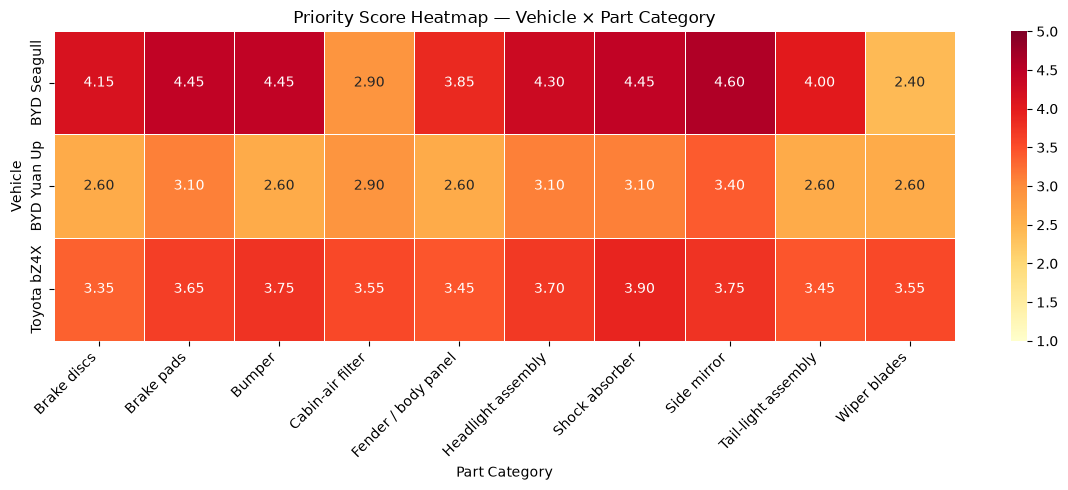

In [7]:
# Heatmap of scores by vehicle and part category
fig, ax = plt.subplots(figsize=(12, 5))

pivot = scores_df.pivot_table(
    values='priority_score',
    index='vehicle',
    columns='part_category'
)

sns.heatmap(pivot, annot=True, fmt='.2f', cmap='YlOrRd', ax=ax,
            linewidths=0.5, vmin=1, vmax=5)
ax.set_title('Priority Score Heatmap — Vehicle × Part Category')
ax.set_xlabel('Part Category')
ax.set_ylabel('Vehicle')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

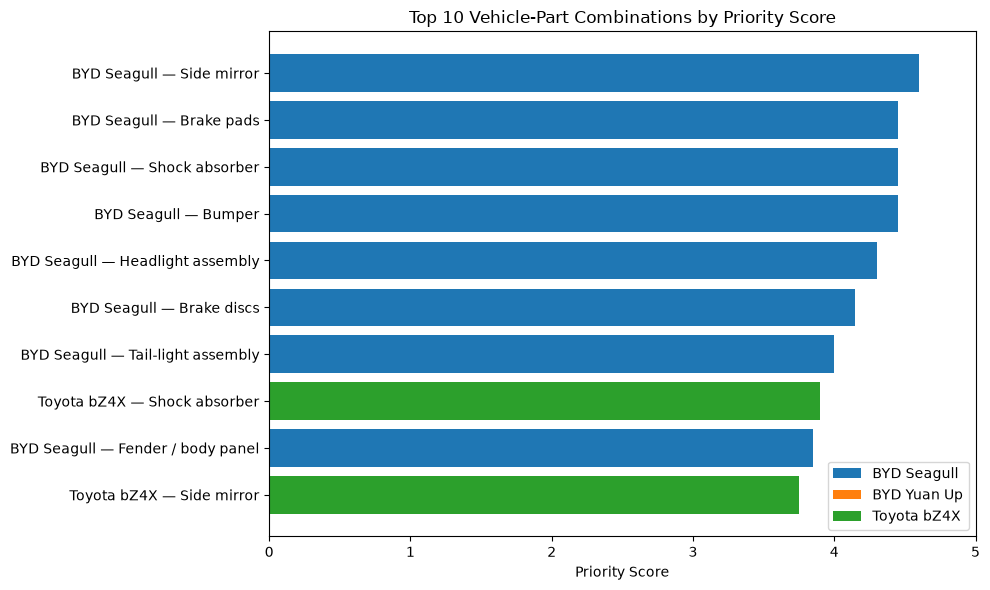

In [8]:
# Bar chart: Top 10 vehicle-part combinations
fig, ax = plt.subplots(figsize=(10, 6))

top10 = scores_df.nlargest(10, 'priority_score').copy()
top10['label'] = top10['vehicle'] + ' — ' + top10['part_category']

colors = {'BYD Seagull': '#1f77b4', 'BYD Yuan Up': '#ff7f0e', 'Toyota bZ4X': '#2ca02c'}
bar_colors = [colors.get(v, '#333333') for v in top10['vehicle']]

ax.barh(top10['label'][::-1], top10['priority_score'][::-1], color=bar_colors[::-1])
ax.set_xlabel('Priority Score')
ax.set_title('Top 10 Vehicle-Part Combinations by Priority Score')
ax.set_xlim(0, 5)

# Add legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=v) for v, c in colors.items()]
ax.legend(handles=legend_elements, loc='lower right')

plt.tight_layout()
plt.show()

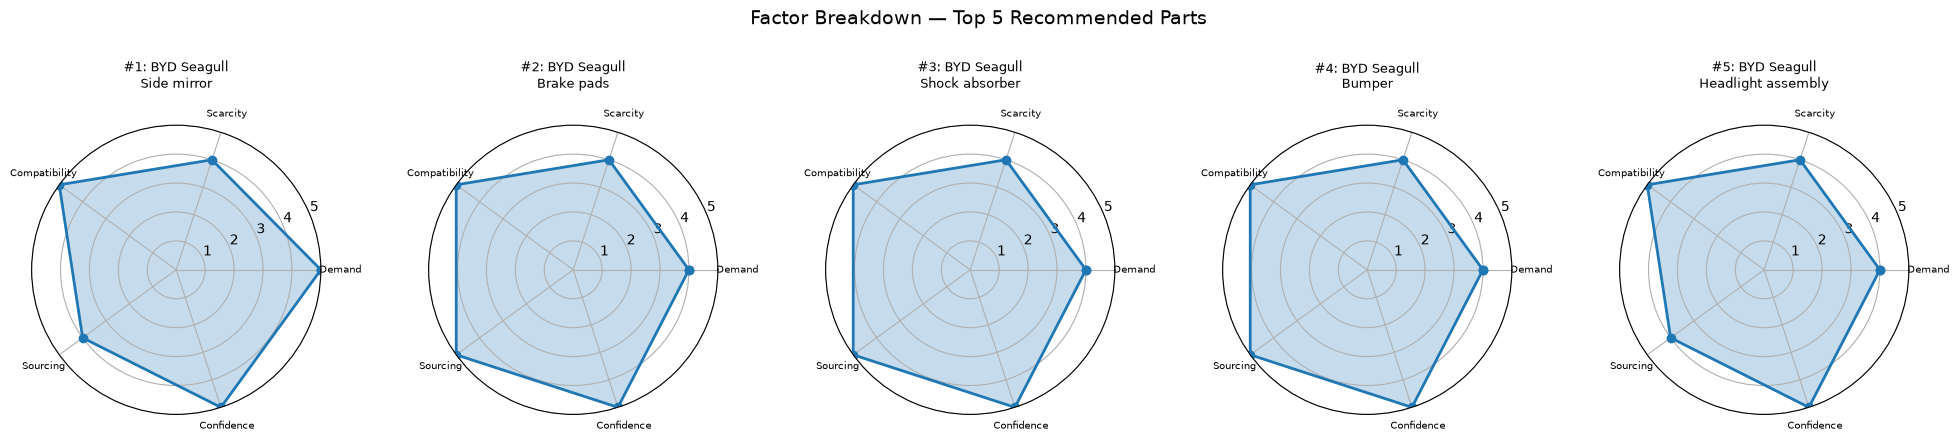

In [9]:
# Radar chart: Factor breakdown for the top 5 recommendations
from math import pi

top5_df = scores_df.nlargest(5, 'priority_score')
factors = ['demand_evidence', 'market_scarcity', 'vehicle_compatibility',
           'sourcing_practicality', 'evidence_confidence']
factor_labels = ['Demand', 'Scarcity', 'Compatibility', 'Sourcing', 'Confidence']

fig, axes = plt.subplots(1, 5, figsize=(20, 4), subplot_kw=dict(polar=True))

for idx, (_, row) in enumerate(top5_df.iterrows()):
    ax = axes[idx]
    values = [row[f] for f in factors]
    values += values[:1]  # Close the polygon
    
    angles = [n / float(len(factors)) * 2 * pi for n in range(len(factors))]
    angles += angles[:1]
    
    ax.plot(angles, values, 'o-', linewidth=2)
    ax.fill(angles, values, alpha=0.25)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(factor_labels, size=7)
    ax.set_ylim(0, 5)
    ax.set_title(f"#{idx+1}: {row['vehicle']}\n{row['part_category']}", size=9, pad=15)

plt.suptitle('Factor Breakdown — Top 5 Recommended Parts', y=1.05, fontsize=14)
plt.tight_layout()
plt.show()

## 4.6 Final Recommendations

In [10]:
# Display the top 5 recommendations
top5_final = scores_df.nlargest(5, 'priority_score')[[
    'vehicle', 'part_category', 'priority_score',
    'demand_evidence', 'market_scarcity', 'vehicle_compatibility',
    'sourcing_practicality', 'evidence_confidence', 'score_justification'
]].reset_index(drop=True)
top5_final.index = range(1, 6)  # Rank 1-5
top5_final.index.name = 'Rank'

print("=" * 70)
print("FINAL RECOMMENDATIONS: Top 5 EV Spare Parts for Import")
print("=" * 70)
print()
for rank, row in top5_final.iterrows():
    print(f"#{rank}: {row['vehicle']} — {row['part_category']}")
    print(f"   Priority Score: {row['priority_score']:.2f} / 5.00")
    print(f"   Demand={row['demand_evidence']} | Scarcity={row['market_scarcity']} | "
          f"Compat={row['vehicle_compatibility']} | Source={row['sourcing_practicality']} | "
          f"Conf={row['evidence_confidence']}")
    if row['score_justification']:
        print(f"   Justification: {row['score_justification']}")
    print()

print("=" * 70)
print("Note: These are provisional recommendations based on available public evidence.")
print("See reports/limitations.md for data gaps and assumptions.")

FINAL RECOMMENDATIONS: Top 5 EV Spare Parts for Import

#1: BYD Seagull — Side mirror
   Priority Score: 4.60 / 5.00
   Demand=5 | Scarcity=4 | Compat=5 | Source=4 | Conf=5
   Justification: D=5: High Adey Market presence (37 Seagull listings in the collected Adey sample — scrapper/outputs/adey_cleaned.csv) + high exterior contact exposure (indicative demand proxy). S=4: Not carried by the investigated local distributor channel (Gezat S002 review was catalogue/model-level only — no per-part search recorded, so local per-part availability is UNVERIFIED); listed by overseas supplier (Landin S003). C=5: Supplier-listed OE references EQEA-8202100 (LH) / EQEA-8202109 (RH) confirmed in Landin with SEAGULL compatibility statement [OBS019, OBS020 / S003]. P=4: Active catalogue listing; primary evaluated application is Left exterior mirror assembly (EQEA-8202100) at 429 RMB ($60.06 USD), falling into the $50-$250 bracket (companion RH mirror EQEA-8202109 is 264 RMB / $36.96 USD). E=5: Landin na

In [11]:
# Save the full scoring table.
#
# SINGLE SOURCE OF TRUTH: data/scoring_results.csv is produced by the authoritative scoring
# module (scrapper/generate_scores_defensible.py). To guarantee this notebook can never overwrite
# the published artifact with placeholder or incomplete data, the export is delegated to the
# module's calculate_scores() rather than written from a notebook-local recomputation.
from scrapper.generate_scores_defensible import calculate_scores

authoritative = calculate_scores()

# Safety guards: refuse to write anything that is not the complete, non-zero scoring table.
assert len(authoritative) == 30, f"Refusing to write {len(authoritative)} rows (expected 30)"
assert (authoritative['priority_score'] > 0).all(), "Refusing to write zero-filled scores"

authoritative.to_csv('../data/scoring_results.csv', index=False)
print(f"Scoring results saved to data/scoring_results.csv ({len(authoritative)} rows)")

# Round-trip verification that the exported CSV parses and carries real scores
check = pd.read_csv('../data/scoring_results.csv')
print(f"Verification: {check.shape[0]} rows x {check.shape[1]} columns reloaded OK; "
      f"max priority_score = {check['priority_score'].max():.2f}")

Scoring results saved to data/scoring_results.csv (30 rows)
Verification: 30 rows x 14 columns reloaded OK; max priority_score = 4.60
